In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Dataset: Burgers' shock formation

In [3]:
from scipy.io import loadmat
data = loadmat(os.path.expanduser('~/data10/DATA442/burgers_shock.mat'))

u_data = data['usol']
t_data = data['t']
x_data = data['x']

print(u_data.shape, t_data.shape, x_data.shape)

(256, 100) (100, 1) (256, 1)


In [4]:
# Save these for bookkeeping

N = x_data.shape[0]
T = t_data.shape[0]

dt = t_data[1, 0] - t_data[0, 0]
dx = x_data[1, 0] - x_data[0, 0]

# For plotting
XX = np.tile(x_data, (1, T)) #[N, T]
TT = np.tile(t_data.T, (N, 1)) #[N, T]

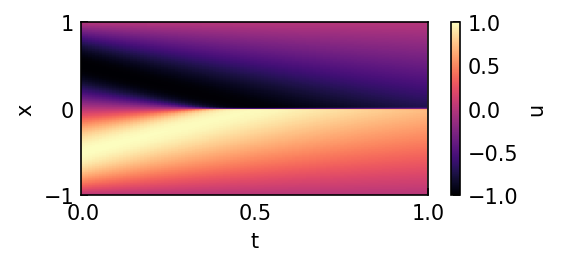

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(4, 1.5))
im = ax.pcolormesh(TT, XX, u_data, cmap='magma', vmin=-1, vmax=1)
ax.set(
    xlabel='t', xticks=[0, 0.5, 1],
    ylabel='x', yticks=[-1, 0, 1],
    aspect=0.25
)
plt.colorbar(im, ax=ax, label='u');

### Select PINN data and collocation points

In [6]:
x_all = XX.flatten()
t_all = TT.flatten()
u_all = u_data.flatten()

# Select N_b boundary points for reconstruction loss
N_b = 200
idx = np.argwhere(
    np.logical_or(
        np.logical_or(x_all == x_all.min(), x_all == x_all.max()),
        np.logical_or(t_all == t_all.min(), t_all == t_all.max())
    )
)[:, 0]
idx = np.random.choice(idx, N_b, replace=False)
x_b, t_b, u_b = x_all[idx, None], t_all[idx, None], u_all[idx, None]

# Select N_p interior points for physics loss
N_p = 2000
idx = np.random.choice(N*T, N_p, replace=False)
x_p, t_p, u_p = x_all[idx, None], t_all[idx, None], u_all[idx, None]

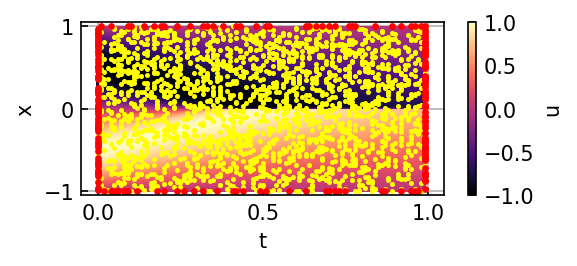

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(4, 1.5))
im = ax.pcolormesh(TT, XX, u_data, cmap='magma', vmin=-1, vmax=1)
ax.set(
    xlabel='t', xticks=[0, 0.5, 1], xlim=[-0.05, 1.05],
    ylabel='x', yticks=[-1, 0, 1], ylim=[-1.05, 1.05],
    aspect=0.25
)
plt.colorbar(im, ax=ax, label='u');

ax.scatter(t_p, x_p, c='yellow', marker='o', s=2)
ax.scatter(t_b, x_b, c='red', marker='o', s=5)


## Solve for interior points using NN

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.notebook import trange

base_nn = nn.Sequential(
    nn.Linear(2, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 1)
).to(device)

optimizer = torch.optim.Adam(base_nn.parameters(), lr=1e-3)

n_iter = 5000

if not torch.is_tensor(x_b):
    x_b = torch.tensor(x_b, dtype=torch.float32, device=device)
    t_b = torch.tensor(t_b, dtype=torch.float32, device=device)
    u_b = torch.tensor(u_b, dtype=torch.float32, device=device)

xt_b = torch.concat([x_b, t_b], dim=1)

for ii in trange(n_iter):
    # Run model on boundary points and minimize MSE loss
    u_pred = base_nn(xt_b)
    loss = F.mse_loss(u_b, u_pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if ii % 1000 == 0:
        print(f'Iteration {ii:03d} / {n_iter:03d}: MSE = {loss:.5e}')

  0%|          | 0/5000 [00:00<?, ?it/s]

Iteration 000 / 5000: MSE = 2.35390e-01
Iteration 1000 / 5000: MSE = 3.15253e-04
Iteration 2000 / 5000: MSE = 1.03475e-04
Iteration 3000 / 5000: MSE = 4.79921e-05
Iteration 4000 / 5000: MSE = 6.23108e-05


Interior MSE loss = 6.29859e-02


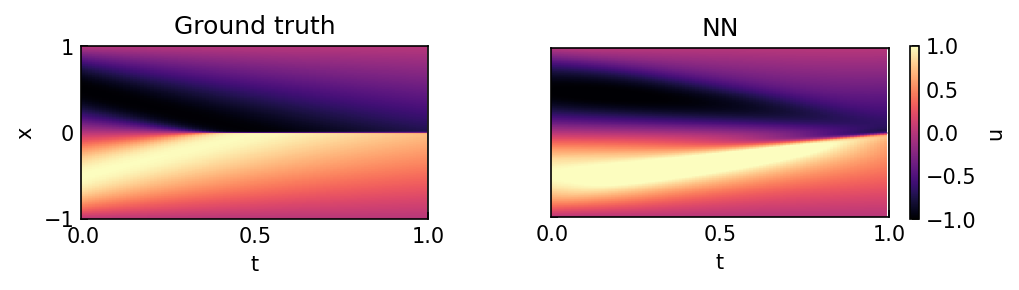

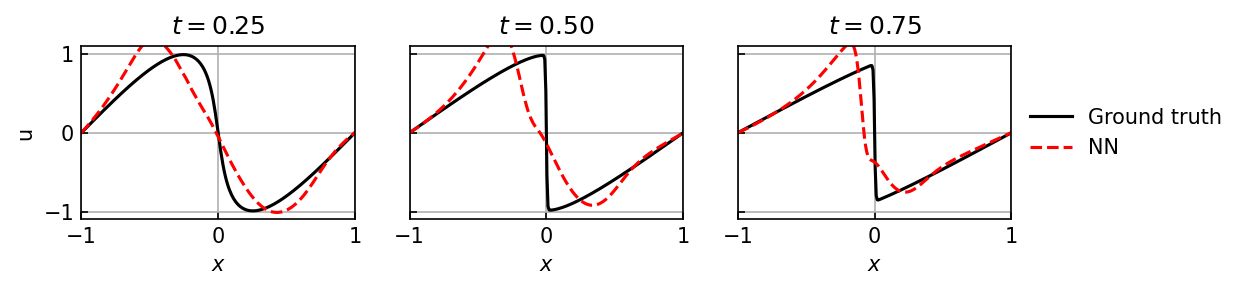

In [9]:
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 1.5))

im = ax[0].pcolormesh(TT, XX, u_data, cmap='magma', vmin=-1, vmax=1)
ax[0].set(
    xlabel='t', xticks=[0, 0.5, 1],
    ylabel='x', yticks=[-1, 0, 1],
    aspect=0.25
)
ax[0].set_title('Ground truth')

xt = torch.FloatTensor(np.stack([x_all, t_all], axis=-1)).to(device)
u_pred = base_nn(xt).detach().cpu().numpy()
u_pred = u_pred.reshape(u_data.shape)

im = ax[1].pcolormesh(TT, XX, u_pred, cmap='magma', vmin=-1, vmax=1)
ax[1].set(
    xlabel='t', xticks=[0, 0.5, 1],
    aspect=0.25
)
plt.colorbar(im, ax=ax[1], label='u');
ax[1].set_title('NN')

# Interior MSE
mse_loss = np.mean((u_pred - u_data)**2)
print(f'Interior MSE loss = {mse_loss:.5e}')

fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(8, 1.5))

ax[0].plot(x_data, u_data[:,25], color='black', label='Ground truth')
ax[1].plot(x_data, u_data[:,50], color='black', label='Ground truth')
ax[2].plot(x_data, u_data[:,75], color='black', label='Ground truth')

ax[0].plot(x_data, u_pred[:,25], color='red', linestyle='--', label='NN')
ax[1].plot(x_data, u_pred[:,50], color='red', linestyle='--', label='NN')
ax[2].plot(x_data, u_pred[:,75], color='red', linestyle='--', label='NN')

ax[0].set_title(f'$t = {t_data[25,0]:.2f}$')
ax[1].set_title(f'$t = {t_data[50,0]:.2f}$')
ax[2].set_title(f'$t = {t_data[75,0]:.2f}$')

for a in ax:
    a.set(xlabel='$x$', xlim=[-1, 1], xticks=[-1, 0, 1], 
          ylim=[-1.1, 1.1], yticks=[-1, 0, 1])
ax[0].set_ylabel('u')
ax[-1].legend(loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0);

## Solve for interior points using PINN

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.notebook import trange

if not torch.is_tensor(x_b):
    x_b = torch.tensor(x_b, dtype=torch.float32, device=device)
    t_b = torch.tensor(t_b, dtype=torch.float32, device=device)
    u_b = torch.tensor(u_b, dtype=torch.float32, device=device)
    
xt_b = torch.concat([x_b, t_b], dim=1)

if not torch.is_tensor(x_p):
    x_p = torch.tensor(x_p, dtype=torch.float32, device=device, requires_grad=True)
    t_p = torch.tensor(t_p, dtype=torch.float32, device=device, requires_grad=True)

pinn_bvp = nn.Sequential(
    nn.Linear(2, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 1)
).to(device)

pinn_bvp.num_iter = 0

optimizer = torch.optim.LBFGS(
    pinn_bvp.parameters(),
    lr=1e0,
    max_iter=50000,
    history_size=50,
    tolerance_grad=1e-9,
    tolerance_change=1.0 * np.finfo(float).eps,
    line_search_fn='strong_wolfe'
)

def pinn_step():
    # Run model on boundary points and get MSE loss
    u_pred = pinn_bvp(xt_b)
    mse_loss = F.mse_loss(u_b, u_pred)

    # Run model on interior points and evaluate phys loss
    u_phys = pinn_bvp(torch.cat([x_p, t_p], dim=-1))

    # Compute gradients w.r.t. inputs
    u_t = torch.autograd.grad(u_phys.sum(), t_p, create_graph=True)[0]
    u_x = torch.autograd.grad(u_phys.sum(), x_p, create_graph=True, retain_graph=True)[0]
    u_xx = torch.autograd.grad(u_x.sum(), x_p, create_graph=True)[0]

    eq = u_t + u_phys * u_x - 0.01 / np.pi * u_xx
    phys_loss = eq.pow(2).mean()

    loss = mse_loss + phys_loss
    
    optimizer.zero_grad()
    loss.backward()
    
    if pinn_bvp.num_iter % 1000 == 0:
        print(f'Iteration {pinn_bvp.num_iter:03d} : MSE = {mse_loss:.5e} \t Phys = {phys_loss:.5e}')
    pinn_bvp.num_iter += 1

    return loss

optimizer.step(pinn_step)
print('Done!')

Iteration 000 : MSE = 2.56761e-01 	 Phys = 1.77731e-03
Iteration 1000 : MSE = 6.89213e-03 	 Phys = 3.82969e-03
Iteration 2000 : MSE = 3.28438e-03 	 Phys = 1.31997e-03
Iteration 3000 : MSE = 1.46056e-03 	 Phys = 6.12239e-04
Iteration 4000 : MSE = 9.73628e-04 	 Phys = 4.61880e-04
Iteration 5000 : MSE = 2.30330e-04 	 Phys = 3.74281e-04
Iteration 6000 : MSE = 1.66594e-04 	 Phys = 1.91555e-04
Iteration 7000 : MSE = 1.18735e-04 	 Phys = 1.14367e-04
Done!


Interior MSE loss = 1.00209e-03


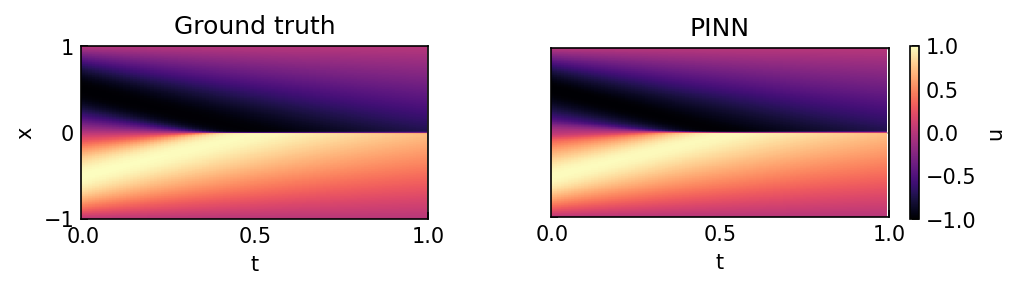

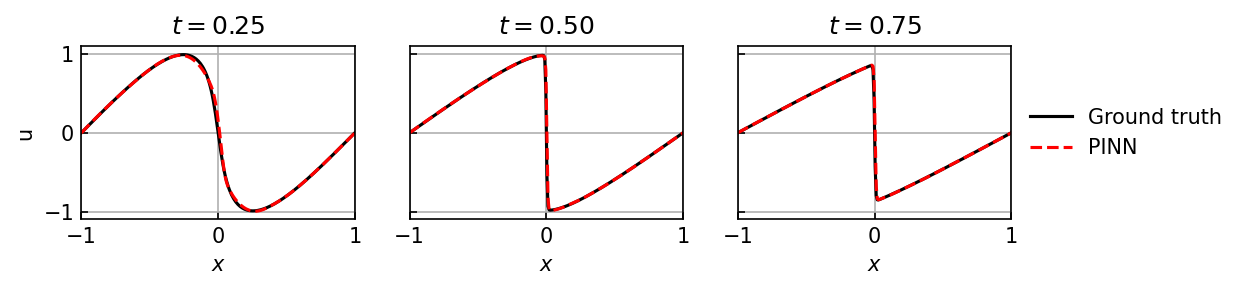

In [11]:
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 1.5))

im = ax[0].pcolormesh(TT, XX, u_data, cmap='magma', vmin=-1, vmax=1)
ax[0].set(
    xlabel='t', xticks=[0, 0.5, 1],
    ylabel='x', yticks=[-1, 0, 1],
    aspect=0.25
)
ax[0].set_title('Ground truth')

xt = torch.FloatTensor(np.stack([x_all, t_all], axis=-1)).to(device)
u_pred = pinn_bvp(xt).detach().cpu().numpy()
u_pred = u_pred.reshape(u_data.shape)

im = ax[1].pcolormesh(TT, XX, u_pred, cmap='magma', vmin=-1, vmax=1)
ax[1].set(
    xlabel='t', xticks=[0, 0.5, 1],
    aspect=0.25
)
plt.colorbar(im, ax=ax[1], label='u');
ax[1].set_title('PINN')

# Interior MSE
mse_loss = np.mean((u_pred - u_data)**2)
print(f'Interior MSE loss = {mse_loss:.5e}')

fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(8, 1.5))

ax[0].plot(x_data, u_data[:,25], color='black', label='Ground truth')
ax[1].plot(x_data, u_data[:,50], color='black', label='Ground truth')
ax[2].plot(x_data, u_data[:,75], color='black', label='Ground truth')

ax[0].plot(x_data, u_pred[:,25], color='red', linestyle='--', label='PINN')
ax[1].plot(x_data, u_pred[:,50], color='red', linestyle='--', label='PINN')
ax[2].plot(x_data, u_pred[:,75], color='red', linestyle='--', label='PINN')

ax[0].set_title(f'$t = {t_data[25,0]:.2f}$')
ax[1].set_title(f'$t = {t_data[50,0]:.2f}$')
ax[2].set_title(f'$t = {t_data[75,0]:.2f}$')

for a in ax:
    a.set(xlabel='$x$', xlim=[-1, 1], xticks=[-1, 0, 1], 
          ylim=[-1.1, 1.1], yticks=[-1, 0, 1])
ax[0].set_ylabel('u')
ax[-1].legend(loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0);

## Identify parameters using PINN

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.notebook import trange

if not torch.is_tensor(u_p):
    u_p = torch.tensor(u_p, dtype=torch.float32, device=device, requires_grad=True)

pinn_param = nn.Sequential(
    nn.Linear(2, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 1)
)

# Add trainable physical parameters
pinn_param.params = nn.Parameter(torch.randn(2), requires_grad=True)
pinn_param.register_parameter('params', pinn_param.params)

pinn_param = pinn_param.to(device)

pinn_param.num_iter = 0

optimizer = torch.optim.LBFGS(
    pinn_param.parameters(),
    lr=1e0,
    max_iter=50000,
    history_size=50,
    tolerance_grad=1e-9,
    tolerance_change=1.0 * np.finfo(float).eps,
    line_search_fn='strong_wolfe'
)

def pinn_step():
    # Run model on interior points and get MSE loss
    u_pred = pinn_param(torch.cat([x_p, t_p], dim=-1))
    mse_loss = F.mse_loss(u_p, u_pred)

    # Run model on interior points and evaluate phys loss given current parameters
    u_phys = pinn_param(torch.cat([x_p, t_p], dim=-1))

    # Compute gradients w.r.t. inputs
    u_t = torch.autograd.grad(u_phys.sum(), t_p, create_graph=True)[0]
    u_x = torch.autograd.grad(u_phys.sum(), x_p, create_graph=True, retain_graph=True)[0]
    u_xx = torch.autograd.grad(u_x.sum(), x_p, create_graph=True)[0]

    lambd = pinn_param.params[0].exp()
    nu = pinn_param.params[1].exp()

    eq = u_t + lambd * u_phys * u_x - nu * u_xx
    phys_loss = eq.pow(2).mean()

    loss = mse_loss + phys_loss
    
    optimizer.zero_grad()
    loss.backward()
    
    if pinn_param.num_iter % 1000 == 0:
        print(f'Iteration {pinn_param.num_iter:03d} : MSE = {mse_loss:.5e} \t Phys = {phys_loss:.5e} \t lambda = {lambd:.05e} \t nu = {nu:.05e}')
    pinn_param.num_iter += 1

    return loss

optimizer.step(pinn_step)
print('Done!')

Iteration 000 : MSE = 3.97178e-01 	 Phys = 2.77178e-03 	 lambda = 1.06559e+00 	 nu = 2.35846e+00
Iteration 1000 : MSE = 1.10548e-03 	 Phys = 8.21078e-04 	 lambda = 9.24184e-01 	 nu = 5.01033e-03
Iteration 2000 : MSE = 2.35906e-04 	 Phys = 2.47352e-04 	 lambda = 9.83274e-01 	 nu = 3.73588e-03
Iteration 3000 : MSE = 7.06249e-05 	 Phys = 1.06695e-04 	 lambda = 9.98558e-01 	 nu = 3.55985e-03
Iteration 4000 : MSE = 4.32626e-05 	 Phys = 6.20056e-05 	 lambda = 9.96641e-01 	 nu = 3.35729e-03
Iteration 5000 : MSE = 2.83496e-05 	 Phys = 4.08154e-05 	 lambda = 9.95477e-01 	 nu = 3.18842e-03
Done!


Interior MSE loss = 2.41228e-05


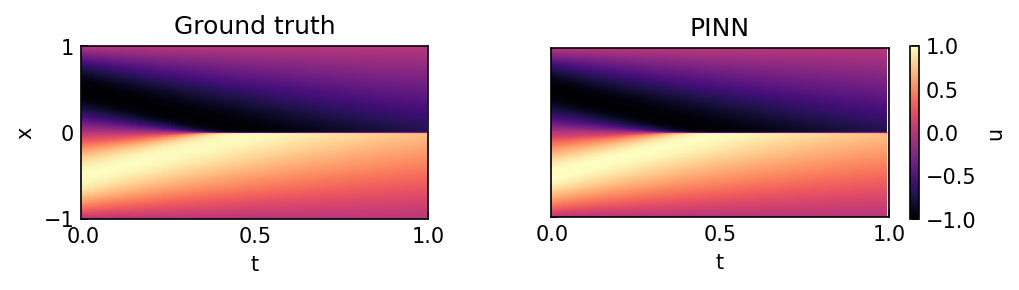

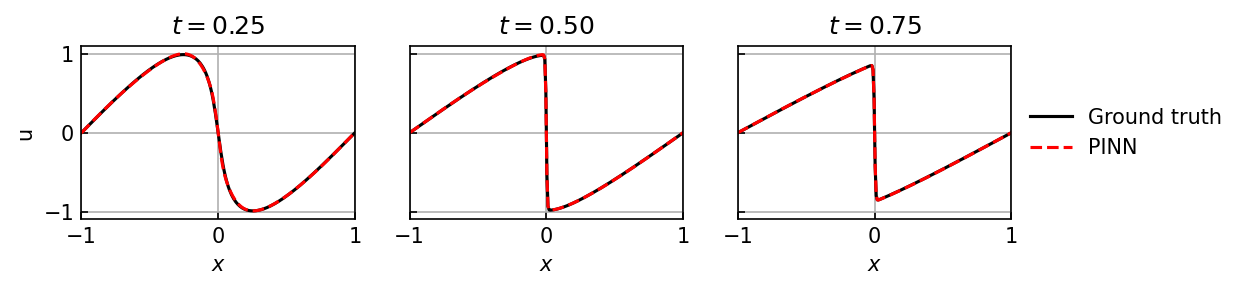

In [13]:
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 1.5))

im = ax[0].pcolormesh(TT, XX, u_data, cmap='magma', vmin=-1, vmax=1)
ax[0].set(
    xlabel='t', xticks=[0, 0.5, 1],
    ylabel='x', yticks=[-1, 0, 1],
    aspect=0.25
)
ax[0].set_title('Ground truth')

xt = torch.FloatTensor(np.stack([x_all, t_all], axis=-1)).to(device)
u_pred = pinn_param(xt).detach().cpu().numpy()
u_pred = u_pred.reshape(u_data.shape)

im = ax[1].pcolormesh(TT, XX, u_pred, cmap='magma', vmin=-1, vmax=1)
ax[1].set(
    xlabel='t', xticks=[0, 0.5, 1],
    aspect=0.25
)
plt.colorbar(im, ax=ax[1], label='u');
ax[1].set_title('PINN')

# Interior MSE
mse_loss = np.mean((u_pred - u_data)**2)
print(f'Interior MSE loss = {mse_loss:.5e}')

fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(8, 1.5))

ax[0].plot(x_data, u_data[:,25], color='black', label='Ground truth')
ax[1].plot(x_data, u_data[:,50], color='black', label='Ground truth')
ax[2].plot(x_data, u_data[:,75], color='black', label='Ground truth')

ax[0].plot(x_data, u_pred[:,25], color='red', linestyle='--', label='PINN')
ax[1].plot(x_data, u_pred[:,50], color='red', linestyle='--', label='PINN')
ax[2].plot(x_data, u_pred[:,75], color='red', linestyle='--', label='PINN')

ax[0].set_title(f'$t = {t_data[25,0]:.2f}$')
ax[1].set_title(f'$t = {t_data[50,0]:.2f}$')
ax[2].set_title(f'$t = {t_data[75,0]:.2f}$')

for a in ax:
    a.set(xlabel='$x$', xlim=[-1, 1], xticks=[-1, 0, 1], 
          ylim=[-1.1, 1.1], yticks=[-1, 0, 1])
ax[0].set_ylabel('u')
ax[-1].legend(loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0);

In [25]:
def relative_error(true, pred):
    return np.abs(true - pred) / true * 100

lambd = pinn_param.params[0].exp().detach().cpu().numpy()
nu = pinn_param.params[1].exp().detach().cpu().numpy()

print(f'Model found lambda = {lambd:.03e}, should be {1.:.03e}. \t Relative error: {relative_error(1, lambd):.02f} %')
print(f'Model found nu = {nu:.03e}, should be {0.01 / np.pi:.03e}. \t Relative error: {relative_error(0.01 / np.pi, nu):.02f} %')

Model found lambda = 9.967e-01, should be 1.000e+00. 	 Relative error: 0.33 %
Model found nu = 3.194e-03, should be 3.183e-03. 	 Relative error: 0.35 %
